Name: Ivy Cheng

Github Username: ivychengusc

USC ID: 6931463618

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## (a)(i)

In [2]:
# Load the student performance dataset
DATA_PATH = "../data/student/student-mat.csv"

df = pd.read_csv(DATA_PATH, sep=";")

# Display the first five rows
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [4]:
# Display summary statistics
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [5]:
# Check missing values
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

## (a)(ii)

In [6]:
# Select the required features
selected_features = [
    "age", "studytime", "schoolsup", "goout",
    "Dalc", "Walc", "health", "absences", "G3"
]

data = df[selected_features].copy()

# Encode schoolsup: no = 0, yes = 1
data["schoolsup"] = data["schoolsup"].map({"no": 0, "yes": 1})

# Combine weekday and weekend alcohol consumption
data["alc"] = (data["Dalc"] + data["Walc"]) / 2

# Remove Dalc and Walc
data = data.drop(columns=["Dalc", "Walc"])

# Display the first five rows of the pre-processed dataset
data.head()

,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5


## (a)(iii)

In [7]:
# Select independent variables
X = data.drop(columns=["G3"])

# Count outliers for each independent variable using the IQR method
outlier_counts = {}

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ]

    outlier_counts[column] = len(outliers)

# Display the number of outliers for each independent variable
outlier_counts_df = pd.DataFrame(
    list(outlier_counts.items()),
    columns=["Feature", "Number of Outliers"]
)

outlier_counts_df

,Feature,Number of Outliers
0,age,1
1,studytime,27
2,schoolsup,51
3,goout,0
4,health,0
5,absences,15
6,alc,9


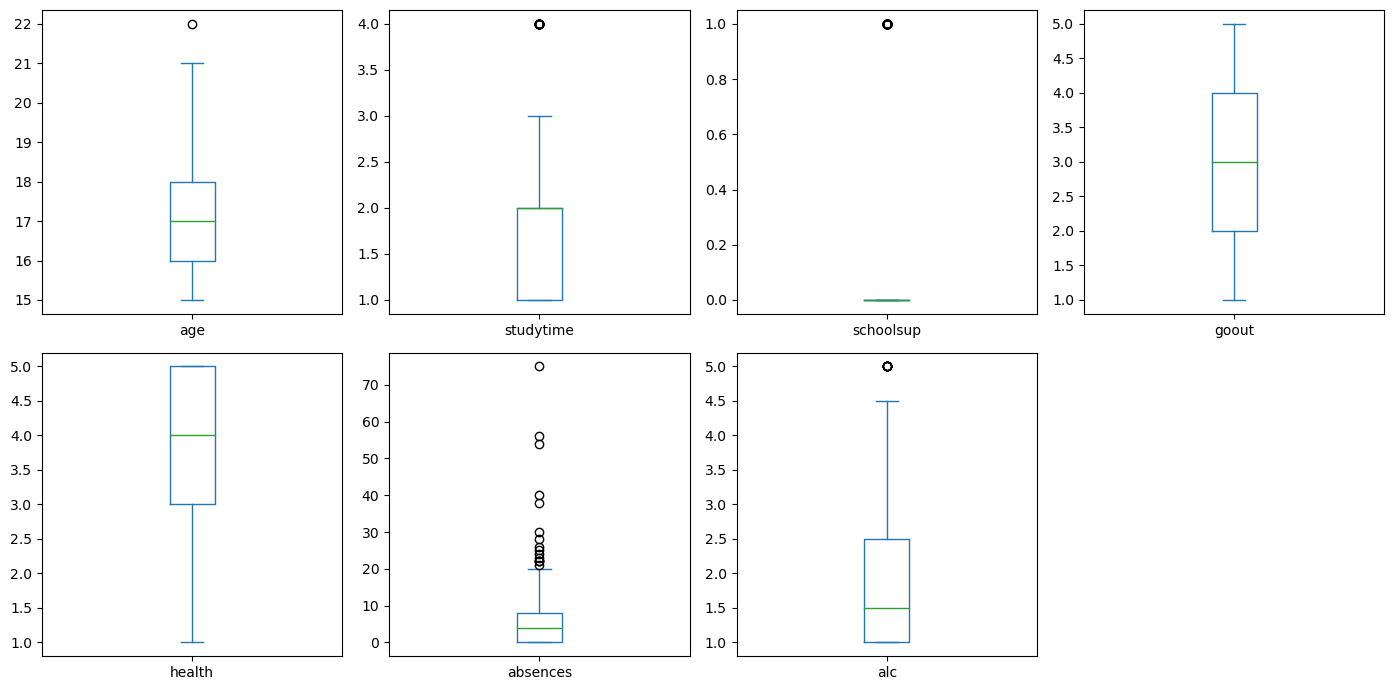

In [8]:
# Create boxplots for outlier detection
X.plot(
    kind="box",
    subplots=True,
    layout=(2, 4),
    figsize=(14, 7),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

## (a)(iv)

In [9]:
# Standardize the independent variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Store the standardized data as a DataFrame for later problems
X_standardized = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

# Display the first five rows
X_standardized.head()

,age,studytime,schoolsup,goout,health,absences,alc
0,1.023046,-0.042286,2.597133,0.801479,-0.399289,0.036424,-0.894179
1,0.238380,-0.042286,-0.385040,-0.097908,-0.399289,-0.213796,-0.894179
2,-1.330954,-0.042286,2.597133,-0.997295,-0.399289,0.536865,0.619538
3,-1.330954,1.150779,-0.385040,-0.997295,1.041070,-0.464016,-0.894179
4,-0.546287,-0.042286,-0.385040,-0.997295,1.041070,-0.213796,-0.389607


In [10]:
# Run PCA using two principal components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_standardized)

# Create a DataFrame with PC1, PC2, and final grade G3
pca_df = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"],
    index=X.index
)

pca_df["G3"] = data["G3"]

pca_df.head()

,PC1,PC2,G3
0,-0.398920,-0.319499,6
1,-0.472653,0.682285,6
2,-1.144004,-1.778275,10
3,-1.863589,-0.279980,15
4,-0.799752,-0.370087,10


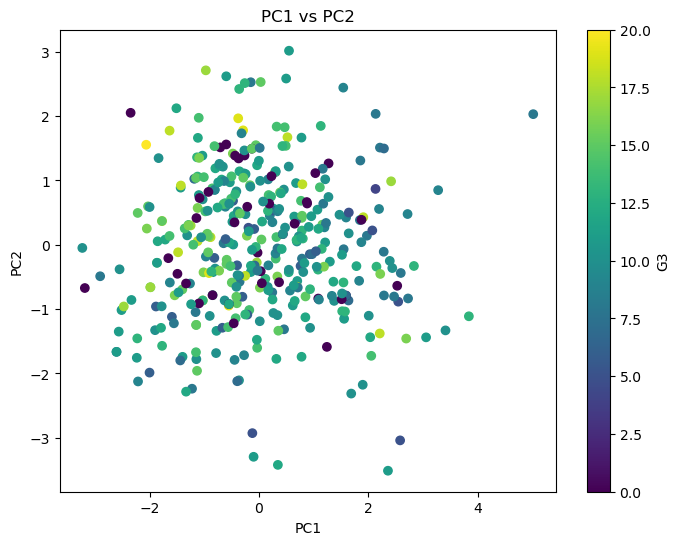

In [11]:
# Create a scatterplot of PC1 versus PC2 colored by final grade G3
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["G3"],
    cmap="viridis"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PC1 vs PC2")
plt.colorbar(scatter, label="G3")
plt.show()

In [12]:
# Calculate PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

loadings

,PC1,PC2
age,0.381940,0.589260
studytime,-0.329734,0.385671
schoolsup,-0.248184,-0.464202
goout,0.493755,-0.139613
health,0.080545,-0.400925
absences,0.280106,0.182798
alc,0.595871,-0.273677


In [13]:
# Find the features with the largest absolute loadings
pc1_feature = loadings["PC1"].abs().idxmax()
pc2_feature = loadings["PC2"].abs().idxmax()

print("Largest contributor to PC1:", pc1_feature)
print("Largest contributor to PC2:", pc2_feature)

Largest contributor to PC1: alc
Largest contributor to PC2: age


In [14]:
# Display explained variance ratios
print("PC1 explained variance ratio:", pca.explained_variance_ratio_[0])
print("PC2 explained variance ratio:", pca.explained_variance_ratio_[1])

PC1 explained variance ratio: 0.23675737989229545
PC2 explained variance ratio: 0.1713659790584984


The PCA results show that alc has the largest absolute loading on PC1, while age has the largest absolute loading on PC2. PC1 explains about 23.68% of the total variance and PC2 explains about 17.14%, so the first two principal components explain about 40.82% of the variance together. From the scatter plot, the G3 values are mixed across the plot and there is no clear separation based on PC1 and PC2.

## (b)(i)

In [15]:
# Separate independent variables and dependent variable
X_model = X_standardized
y = data["G3"]

# Split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=552
)

# Display the shapes of the training and testing sets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (316, 7)
X_test shape: (79, 7)
y_train shape: (316,)
y_test shape: (79,)


## (b)(ii)

In [16]:
# Build the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Build the Ridge Regression model with alpha = 0.1
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train, y_train)

# Build the Lasso Regression model with alpha = 0.1
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)

print("Linear Regression model fitted.")
print("Ridge Regression model fitted.")
print("Lasso Regression model fitted.")

Linear Regression model fitted.
Ridge Regression model fitted.
Lasso Regression model fitted.


## (b)(iii)

In [17]:
# Make predictions on the test set
y_pred_linear = linear_model.predict(X_test)
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

# Calculate evaluation metrics
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_linear),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_lasso)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_linear)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso))
    ],
    "R2": [
        r2_score(y_test, y_pred_linear),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso)
    ]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,3.418009,4.755812,0.028177
1,Ridge Regression,3.418062,4.755859,0.028157
2,Lasso Regression,3.447073,4.793840,0.012573


In [18]:
# Find the best performing model for each metric
best_mae_model = results.loc[results["MAE"].idxmin(), "Model"]
best_rmse_model = results.loc[results["RMSE"].idxmin(), "Model"]
best_r2_model = results.loc[results["R2"].idxmax(), "Model"]

print("Best model by MAE:", best_mae_model)
print("Best model by RMSE:", best_rmse_model)
print("Best model by R2:", best_r2_model)

Best model by MAE: Linear Regression
Best model by RMSE: Linear Regression
Best model by R2: Linear Regression


Linear Regression performs the best among the three models because it has the lowest MAE and RMSE and the highest \(R^2\). Ridge Regression gives almost the same performance, while Lasso Regression performs slightly worse.

## (b)(iv)

The \(R^2\) values are very low for all three models. Linear Regression and Ridge Regression have \(R^2\) values of about 0.028, while Lasso Regression has an \(R^2\) of about 0.013. This means the models explain only a small percentage of the variation in G3, so the selected features have weak predictive power for final grade.

## (b)(v)

In [19]:
# Create a table of coefficients for all three models
coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Linear Regression": linear_model.coef_,
    "Ridge Regression": ridge_model.coef_,
    "Lasso Regression": lasso_model.coef_
})

coefficient_table

,Feature,Linear Regression,Ridge Regression,Lasso Regression
0,age,-0.781077,-0.780739,-0.630377
1,studytime,0.444812,0.444655,0.349092
2,schoolsup,-0.682472,-0.682191,-0.547461
3,goout,-0.582519,-0.582312,-0.485602
4,health,-0.243324,-0.243227,-0.141569
5,absences,0.192800,0.192695,0.072043
6,alc,0.037073,0.036909,-0.000000


In [20]:
# Display intercepts for all three models
intercept_table = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    "Intercept": [
        linear_model.intercept_,
        ridge_model.intercept_,
        lasso_model.intercept_
    ]
})

intercept_table

,Model,Intercept
0,Linear Regression,10.629378
1,Ridge Regression,10.629365
2,Lasso Regression,10.625104


## (b)(vi)

Ridge Regression shrinks the coefficients toward zero but keeps all features in the model. Lasso Regression can shrink some coefficients exactly to zero, so it can also perform feature selection.

In this dataset, Ridge gives almost the same results as Linear Regression, while Lasso performs slightly worse and sets the coefficient of alc to zero. This suggests that regularization does not improve the model much, and some selected features may have weak predictive power for G3. The low \(R^2\) values also suggest that these features explain only a small part of the variation in final grades.

## (b)(vii)

Ridge Regression shrinks the coefficients toward zero but keeps all features in the model. Lasso Regression can shrink some coefficients exactly to zero, so it can also perform feature selection.

In this dataset, Ridge gives almost the same results as Linear Regression, while Lasso performs slightly worse and sets the coefficient of alc to zero. This suggests that regularization does not improve the model much, and some selected features may have weak predictive power for G3. The low \(R^2\) values also suggest that these features explain only a small part of the variation in final grades.

## (b)(viii)

If the regularization strength \(\alpha\) is increased, the coefficients will be shrunk more strongly toward zero.

For Ridge Regression, the coefficients will become smaller but will usually remain nonzero. For Lasso Regression, more coefficients may become exactly zero.

If $\alpha$ becomes too large, the model may underfit the data, which can increase MAE and RMSE and decrease $R^2$.

## (b)(ix)

Possible feature engineering methods include creating interaction terms between related variables, adding polynomial features for nonlinear relationships, and combining related variables into new features.

Categorical variables such as sex, school, address, and family background variables could also be encoded and added to the model.

Since G1 and G2 are previous grades, including them as predictors would likely improve the prediction of G3 significantly.